In [3]:
import pandas as pd

Data Exploration

In [4]:
data = pd.read_csv('./data/Reviews.csv')
data.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [5]:
print("Shape:", data.shape)
data.info()

Shape: (568454, 10)
<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.0 MB


In [6]:
data.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [7]:
print("Fully duplicated rows:", data.duplicated().sum())


Fully duplicated rows: 0


In [8]:
print("Duplicated review texts:", data["Text"].duplicated().sum())

Duplicated review texts: 174875


score distribution

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


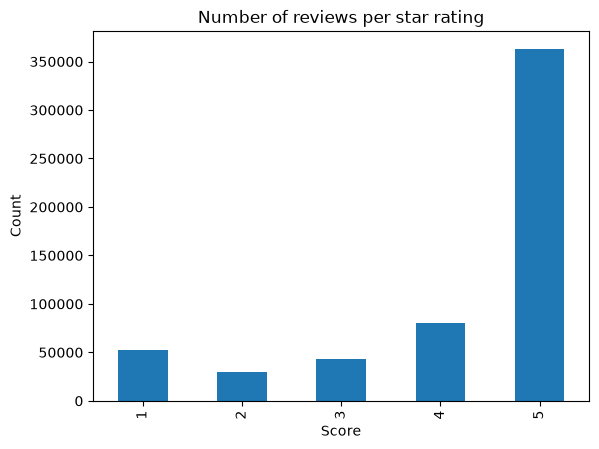

In [9]:
import matplotlib.pyplot as plt

print(data["Score"].value_counts().sort_index())

data["Score"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of reviews per star rating")
plt.xlabel("Score")
plt.ylabel("Count")
plt.show()

In [10]:
df_new = data[["Text", "Score"]].copy()
print("Original rows:", len(df_new))



Original rows: 568454


In [11]:
df_new.isna().sum()

Text     0
Score    0
dtype: int64

In [12]:
df_new.duplicated().sum()

np.int64(174779)

In [13]:
df_new = df_new.drop_duplicates(subset="Text")
print("After removing duplicate reviews:", len(df_new))


After removing duplicate reviews: 393579


In [14]:



df_new = df_new[df_new["Text"].str.split().str.len() >= 3]
print("After removing very short reviews:", len(df_new))

df_new = df_new[df_new["Score"].between(1, 5)]
df_new["Score"] = df_new["Score"].astype(int)
print("Final rows:", len(df_new))

df_new["Score"].value_counts().sort_index()




After removing very short reviews: 393579
Final rows: 393579


Score
1     36275
2     20792
3     29754
4     56042
5    250716
Name: count, dtype: int64

In [15]:
def score_to_label(score):
    if score >= 4:
        return "positive"
    elif score == 3:
        return "neutral"
    else:
        return "negative"

df_new = df_new.copy()
df_new["sentiment"] = df_new["Score"].apply(score_to_label)

print(df_new["sentiment"].value_counts())
print((df_new["sentiment"].value_counts(normalize=True) * 100).round(1))

sentiment
positive    306758
negative     57067
neutral      29754
Name: count, dtype: int64
sentiment
positive    77.9
negative    14.5
neutral      7.6
Name: proportion, dtype: float64


In [16]:
df_final = df_new[["Text", "Score", "sentiment"]]

df_final.to_json("data/reviews.json", orient="records")

df_final[["Text"]].sample(n=200, random_state=1).to_json("data/sample_reviews.json", orient="records")

print("Saved", len(df_final), "reviews to data/reviews.json")

Saved 393579 reviews to data/reviews.json


In [17]:
df_final.head(20).to_json("data/preview_reviews.json", orient="records", indent=4)

data cleaning and model training

In [3]:
import pandas as pd
from utils import clean_text

df_json = pd.read_json("data/reviews.json")
print(df_json.shape)

df_json["clean"] = df_json["Text"].apply(clean_text)

for i in range(3):
    print("ORIGINAL:", df_json["Text"].iloc[i][:200])
    print("CLEANED: ", df_json["clean"].iloc[i][:200])
    print()

ModuleNotFoundError: No module named 'nltk'

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_json["clean"],
    df_json["sentiment"],
    test_size=0.2,
    random_state=42,
    stratify=df_json["sentiment"]
)

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))

NameError: name 'df_json' is not defined